# 03. Trực quan hóa Kết quả từ Checkpoint Đã Train (`resnet18_best.pth`)
Notebook này chạy trực tiếp trên **máy Local** (hoặc Colab) bằng file trọng số **đã train xong** (`resnet18_best.pth` trong `train_results/...` hoặc `checkpoints/`) để in ngay các biểu đồ mà **không cần train lại 20 epochs**:
1. **Ma trận nhầm lẫn của Giới tính** (`Female (0)` vs `Male (1)`).
2. **Ma trận nhầm lẫn của Độ tuổi** (9 nhóm tuổi `0-2` … `70+`).
3. **Biểu đồ t-SNE không gian đặc trưng 512-d** học được từ ResNet-18 theo **Độ tuổi** & **Giới tính**.
4. Biểu đồ `history.csv` hiện có *(lưu ý: biểu đồ tách riêng `Gender Loss vs Age Loss` và `Age Accuracy` từng epoch đã được bổ sung vào `02_train_eval_resnet18.ipynb` cho lần train kế tiếp)*.

In [1]:
import io, json, os, sys, zipfile
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

cur = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(cur, "dataset", "metadata")) and cur != os.path.dirname(cur):
    cur = os.path.dirname(cur)
os.chdir(cur)
if cur not in sys.path:
    sys.path.insert(0, cur)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project Root:", os.getcwd(), "| Device:", device)

Project Root: E:\HOCKY7\Hoc May Va Ung Dung\FINAL-PROJECT | Device: cuda


In [2]:
# Định nghĩa lại ResNet18MultiTask (khớp 100% với checkpoint đã train) & load test_loader
AGE_GROUPS_9 = ["0-2", "3-9", "10-19", "20-29", "30-39", "40-49", "50-59", "60-69", "70+"]

def map_age_to_group_idx(age_val: float) -> int:
    a = int(round(float(age_val)))
    if a <= 2: return 0
    if a <= 9: return 1
    if a <= 19: return 2
    if a <= 29: return 3
    if a <= 39: return 4
    if a <= 49: return 5
    if a <= 59: return 6
    if a <= 69: return 7
    return 8

class BasicBlock(nn.Module):
    expansion = 1
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False), nn.BatchNorm2d(out_channels))
    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + self.shortcut(x))

class ResNet18MultiTask(nn.Module):
    def __init__(self, num_genders=2, dropout=0.3):
        super().__init__()
        self.in_channels = 64
        self.conv1 = nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(3, stride=2, padding=1)
        self.layer1 = self._make_layer(64, 2, 1)
        self.layer2 = self._make_layer(128, 2, 2)
        self.layer3 = self._make_layer(256, 2, 2)
        self.layer4 = self._make_layer(512, 2, 2)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(dropout)
        self.gender_head = nn.Linear(512, num_genders)
        self.age_head = nn.Linear(512, 1)
    def _make_layer(self, out_c, n, s):
        layers = []
        for st in [s] + [1]*(n-1):
            layers.append(BasicBlock(self.in_channels, out_c, st))
            self.in_channels = out_c
        return nn.Sequential(*layers)
    def extract_features(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        return self.avgpool(self.layer4(self.layer3(self.layer2(self.layer1(x))))).flatten(1)
    def forward(self, x):
        feats = self.dropout(self.extract_features(x))
        return self.gender_head(feats), self.age_head(feats).squeeze(1)

with open("dataset/metadata/norm_stats.json", encoding="utf-8") as f:
    ns = json.load(f)
val_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize(ns["mean"], ns["std"])])

class TestDS(Dataset):
    def __init__(self, csv_path):
        self.df = pd.read_csv(csv_path)
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        r = self.df.iloc[idx]
        return val_tf(Image.open(r["image_path"]).convert("RGB")), int(r["gender"]), float(r["age"])

test_ds = TestDS("dataset/metadata/test.csv")
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=0)

# Load checkpoint từ checkpoints/ hoặc trực tiếp từ zip trong train_results/
ZIP_OUT = "train_results/resnet18-base/21-11-2026/output/resnet18_outputs-20261121T043536Z-1-001.zip"
CKPT_LOCAL = "checkpoints/resnet18_best.pth"
model = ResNet18MultiTask().to(device)

if os.path.exists(CKPT_LOCAL):
    ckpt = torch.load(CKPT_LOCAL, map_location=device)
    hist_df = pd.read_csv("results/resnet18/history.csv") if os.path.exists("results/resnet18/history.csv") else None
else:
    with zipfile.ZipFile(ZIP_OUT) as zf:
        ckpt = torch.load(io.BytesIO(zf.read("resnet18_outputs/checkpoints/resnet18_best.pth")), map_location=device)
        hist_df = pd.read_csv(io.BytesIO(zf.read("resnet18_outputs/results/resnet18/history.csv")))

model.load_state_dict(ckpt["model_state_dict"])
model.eval()
print(f"Loaded checkpoint epoch {ckpt.get('epoch')} | Test images: {len(test_ds):,}")

Loaded checkpoint epoch 20 | Test images: 2,479


In [3]:
# Trích xuất đặc trưng 512-d & dự đoán trên toàn tập Test (chạy ~30s trên CPU hoặc ~3s trên GPU)
all_feats, all_probs, all_g_true, all_a_pred, all_a_true = [], [], [], [], []
with torch.no_grad():
    for imgs, genders, ages in test_loader:
        x = imgs.to(device)
        feats = model.extract_features(x)
        g_logits, a_pred = model(x)
        all_feats.append(feats.cpu().numpy())
        all_probs.append(torch.softmax(g_logits, dim=1).cpu().numpy())
        all_g_true.append(genders.numpy())
        all_a_pred.append(a_pred.cpu().numpy())
        all_a_true.append(ages.numpy())

feats_np = np.concatenate(all_feats)
gender_probs = np.concatenate(all_probs)
gender_true = np.concatenate(all_g_true)
gender_pred = np.argmax(gender_probs, axis=1)
age_pred = np.concatenate(all_a_pred)
age_true = np.concatenate(all_a_true)
age_grp_true = np.array([map_age_to_group_idx(v) for v in age_true])
age_grp_pred = np.array([map_age_to_group_idx(v) for v in age_pred])
print("Done inference! Age-Group Acc (9 classes):", round(float(np.mean(age_grp_true == age_grp_pred)) * 100, 2), "%")

Done inference! Age-Group Acc (9 classes): 45.46 %


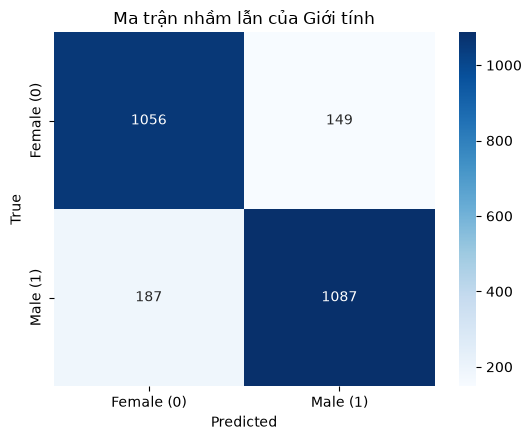

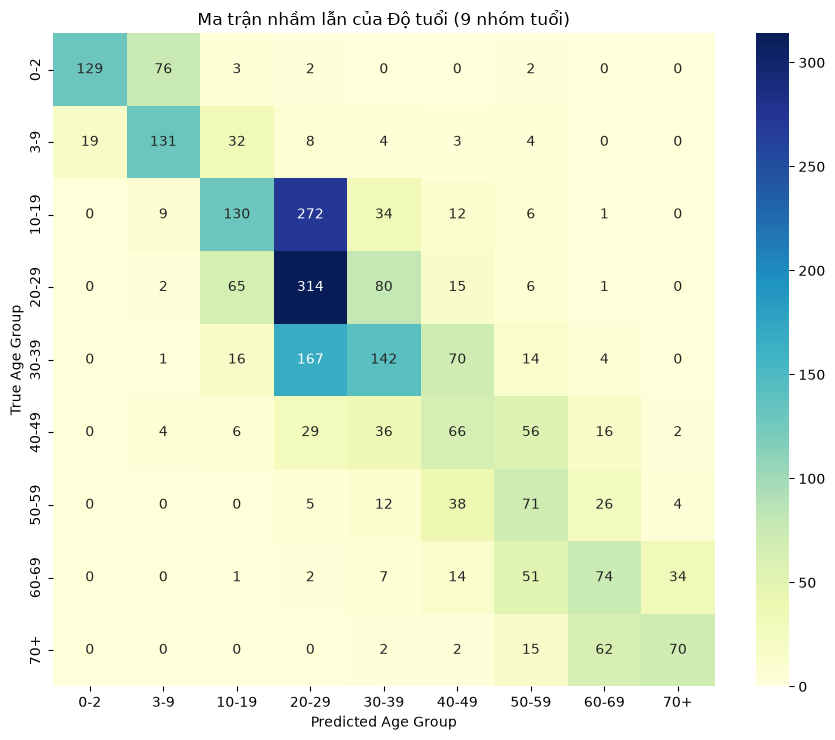

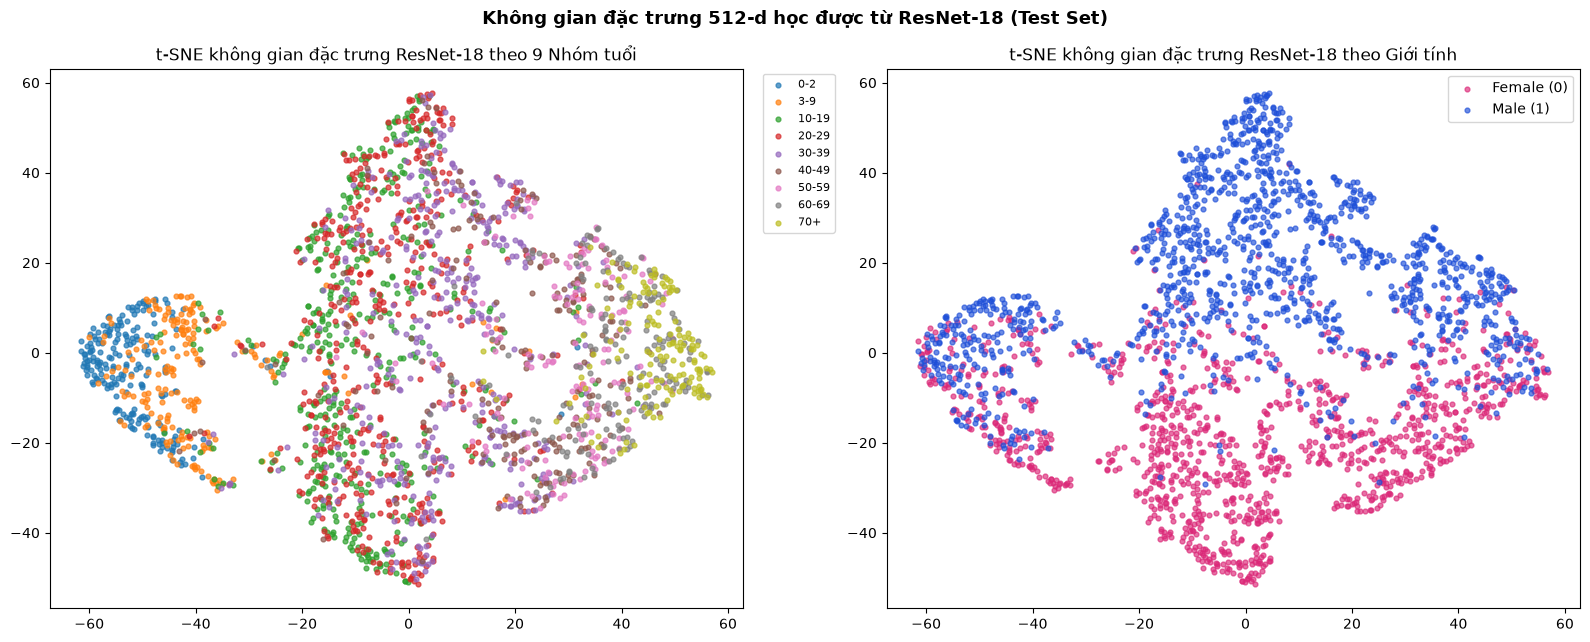

In [4]:
# In 3 biểu đồ trên tập Test: Ma trận nhầm lẫn Giới tính, Ma trận nhầm lẫn Độ tuổi (9x9) & t-SNE không gian đặc trưng
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix

OUT_DIR = "results/resnet18"
os.makedirs(OUT_DIR, exist_ok=True)

# 1. Ma trận nhầm lẫn Giới tính
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(confusion_matrix(gender_true, gender_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Female (0)", "Male (1)"], yticklabels=["Female (0)", "Male (1)"])
plt.title("Ma trận nhầm lẫn của Giới tính"); plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/gender_confusion_matrix.png", dpi=150); plt.show()

# 2. Ma trận nhầm lẫn Độ tuổi (9 nhóm tuổi)
plt.figure(figsize=(9, 7.5))
sns.heatmap(confusion_matrix(age_grp_true, age_grp_pred, labels=list(range(9))), annot=True, fmt="d", cmap="YlGnBu",
            xticklabels=AGE_GROUPS_9, yticklabels=AGE_GROUPS_9)
plt.title("Ma trận nhầm lẫn của Độ tuổi (9 nhóm tuổi)"); plt.xlabel("Predicted Age Group"); plt.ylabel("True Age Group")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/age_confusion_matrix.png", dpi=150); plt.show()

# 3. t-SNE không gian đặc trưng 512-d theo Độ tuổi & Giới tính
X_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(PCA(n_components=50, random_state=42).fit_transform(feats_np))
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
cmap_age = plt.colormaps["tab10"]
for idx, ag in enumerate(AGE_GROUPS_9):
    m = age_grp_true == idx
    axes[0].scatter(X_tsne[m, 0], X_tsne[m, 1], s=12, alpha=0.7, label=ag, color=cmap_age(idx))
axes[0].set_title("t-SNE không gian đặc trưng ResNet-18 theo 9 Nhóm tuổi"); axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
for g_lbl, name, col in [(0, "Female (0)", "#db2777"), (1, "Male (1)", "#1d4ed8")]:
    m = gender_true == g_lbl
    axes[1].scatter(X_tsne[m, 0], X_tsne[m, 1], s=12, alpha=0.65, label=name, color=col)
axes[1].set_title("t-SNE không gian đặc trưng ResNet-18 theo Giới tính"); axes[1].legend()
plt.suptitle("Không gian đặc trưng 512-d học được từ ResNet-18 (Test Set)", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/tsne_age_features.png", dpi=150, bbox_inches="tight"); plt.show()